# QC0426 / VTI — Analysis (round 2)

Analysis notebook for the QC0426 round-2 session (spxtr/measureme `sweep`
data layout: `data/<i>/data.tsv[.gz]` + `metadata.json`). This session's
data ids start at 0; there are no designated reference runs.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute
cells here. Hardware stays on the measure notebook, operator-run.

In [2]:
import os
import json

import numpy as np
import scipy.constants as cst
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt

from sweep import sweep_load as sl

%matplotlib inline

cst_e = cst.e
cst_h = cst.h
Rq = cst_h/cst_e**2

file_path = os.path.join(".", "data")


def load1d(i):
    return np.loadtxt(os.path.join(file_path, "{:d}".format(i), "data.tsv.gz"))

def load_meta(i):
    fp = open(os.path.join(file_path, "{:d}".format(i), "metadata.json"), "r")
    return json.load(fp)

def pretty_load(i):
    data = load1d(i)
    meta = load_meta(i)

    data_dict = {}
    for ind, col in enumerate(meta['columns']):
        data_dict[col] = data[:, ind]

    return data_dict

def pretty_load2d(i):
    data = np.loadtxt(os.path.join(file_path, "{:d}".format(i), "data.tsv"))
    meta = load_meta(i)

    data_dict = {}
    for ind, col in enumerate(meta['columns']):
        data_dict[col] = data[:, ind]

    return data_dict

## (n, D) — capacitance-based convention

Density/displacement from areal gate capacitances (`calc_nD`), **not** the
toploader's `dtg/dbg` constant form. `n` comes out in SI (m^-2; multiply by
1e-16 for 10^12 cm^-2); `D` in V/nm.

In [2]:
cst_epsilon0 = cst.epsilon_0
cst_e = cst.e
cst_h = cst.h
cst_phi0 = cst_h/(2*cst_e)
cst_kappa_SiO2 = 3.9
cst_kappa_hBN = 3

def calc_ctg(t_tg):
    """
    Calculates area capacitance for a top gate
    """
    return cst_epsilon0*cst_kappa_hBN/t_tg

def calc_cbg(t_bg, t_bgSiO2):
    """
    Calculates area capacitance for a back gate
    For a metal back gate, set t_bgSiO2 = 0
    """
    return cst_epsilon0*1/(t_bg/cst_kappa_hBN + t_bgSiO2/cst_kappa_SiO2)

def calc_nD(V_tg, V_bg, c_tg, c_bg, n_offset=0, D_offset = 0):
    n = (1/cst_e) * (c_tg*V_tg  + c_bg*V_bg) + n_offset
    D = 0.5*(c_tg*V_tg - c_bg*V_bg)*1/cst_epsilon0 + D_offset
    return n, D


# Device gate-stack constants — fill in per device (meters)
t_tg = 15.6e-9         # top-gate hBN thickness (geometry prior — calibrate)
t_bg = 12e-9           # back-gate hBN thickness (geometry prior — calibrate)
t_bgSiO2 = 0           # SiO2 term zeroed for QC0426 (n, D) — Si gate is screening, per-run

c_tg = calc_ctg(t_tg)
c_bg = calc_cbg(t_bg, t_bgSiO2)

## Fan re-plot pattern

On this rig the current channel is **`sr0` read through the Ithaco preamp**:
the explicit gain division `I = sr0_X / measurement_config['sr0_gain']` is
**mandatory** — skipping it inverts/rescales every R. (`sr0_gain` is negative,
e.g. -1e6.) The on-disk `plot.png` is only the live monitor; always re-form
R from the TSV.

In [3]:
# PATTERN — Landau-fan re-plot (set the file id).
dat = sl.pload(file_path, <FILE_ID>)

n, D = calc_nD(dat['xs'][0], dat['xs'][1], c_tg, c_bg)
n_12cm = n * 1e-16  # 10^12 cm^-2
ys = dat['ys'][0]   # B (T)

# Current — explicit gain division is MANDATORY on this rig
curr = dat['sr0_X'] / dat['measurement_config']['sr0_gain']

r_xx = ['sr1_X', 'sr2_X']
r_xy = ['sr3_X']

nu = <NU>
nn = cst.e * ys * nu / cst.h * 1e-16  # filling-factor line n = nu·e·B/h, in 10^12 cm^-2

norm = mcolors.SymLogNorm(linthresh=50, vmin=0, vmax=100e3)
for r_xx_pair in r_xx:
    data = dat[r_xx_pair] / curr
    plt.figure()
    plt.pcolormesh(n_12cm, ys, data, cmap='viridis', norm=norm)
    plt.colorbar(label='$R_{xx}$ (Ohms)')
    plt.xlabel('$n$ 10$^{12}$ (cm$^{-2}$)')
    plt.ylabel('$B$ (T)')

h_e2 = cst.h/cst.e**2
for r_xy_pair in r_xy:
    data = dat[r_xy_pair] / curr
    plt.figure()
    plt.pcolormesh(n_12cm, ys, data, cmap='seismic',
                   vmax=h_e2/nu, vmin=-h_e2/nu)
    plt.colorbar(label='$R_{xy}$ (Ohms)')
    plt.xlabel('$n$ 10$^{12}$ (cm$^{-2}$)')
    plt.ylabel('$B$ (T)')
    plt.plot(nn, ys, '--')

plt.figure(dpi=240)
plt.pcolormesh(n_12cm, ys, curr*1e9, cmap='inferno')
plt.colorbar(label='I (nA)')
plt.xlabel('$n$ 10$^{12}$ (cm$^{-2}$)')
plt.ylabel('$B$ (T)')

SyntaxError: invalid syntax (597171912.py, line 2)

## Filling-factor overlay pattern

In [ ]:
# PATTERN — filling-factor overlay: nu lines n = nu·e·B/h on the current fan
# axes (n axis in 10^12 cm^-2 → factor 1e-16 from SI m^-2).
for nu in [<NU_LIST>]:
    nn = cst.e * ys * nu / cst.h * 1e-16
    plt.plot(nn, ys, '--', lw=1, label=rf'$\nu = {nu}$')
plt.legend()

## Phase 1 — CNP / D-line calibration (file_id 18, settled 4τ gate map)

Re-form the 0 T TG–BG map per channel, argmax the Rxx ridge per BG row, fit `Vtg = slope·Vbg + b` (slope = −c_bg/c_tg). Anchor c_tg at the 15.6 nm hBN geometry prior; ratio data-calibrated from sr1. Two-tier provenance: **ratio data-calibrated, absolute scale geometry-prior** until a QH lever-arm check.

sr1 T3-T4: slope=-1.3136 b=+0.2118V  c_bg/c_tg=1.3136  RMS=102mV rows=16/17
sr2 B4-B5: slope=-1.3085 b=+0.1726V  c_bg/c_tg=1.3085  RMS=113mV rows=16/17
c_tg=1.7027e-03 c_bg=2.2367e-03 ratio=1.3136 (geom prior 1.300)  n_offset=-0.225 [1e12 cm^-2]


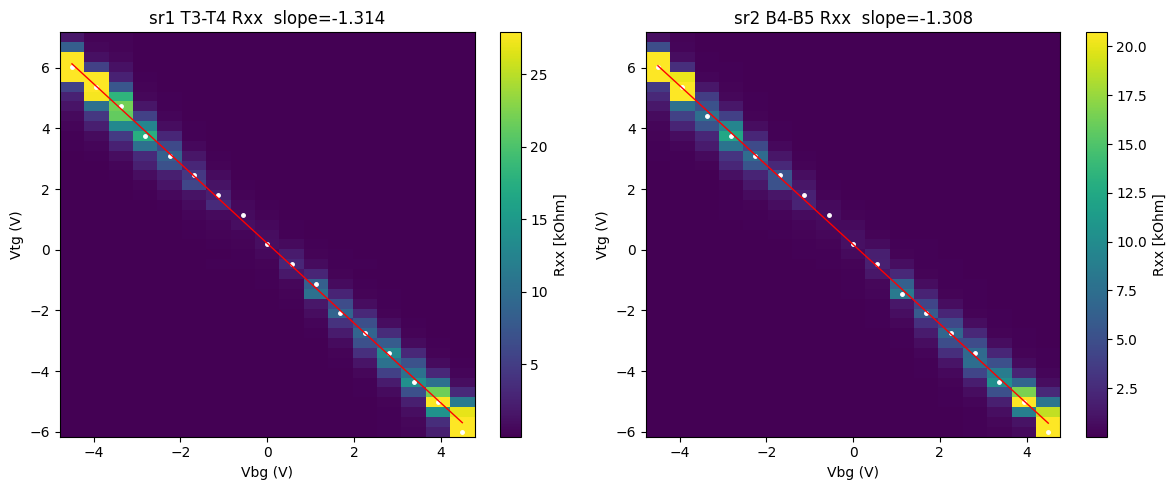

In [5]:
# Phase 1 — CNP / D-line calibration from the settled 0T gate map (file_id 18).
import gzip
from scipy.ndimage import gaussian_filter1d
from sharpelab_nb.gates import stack_capacitance, calc_nD as g_calc_nD, calc_gate_voltages

file_path = r'C:\Users\DGG\VTI_local_data\zack\20260614-QC0426\data'  # ana kernel cwd differs; absolute
FID = 18
meta = load_meta(FID); cols = meta['columns']; ci = {c:i for i,c in enumerate(cols)}
d = load1d(FID)
bg = np.array(meta['slow_setpoints']); tg = np.array(meta['fast_setpoints'])
nbr, nf = len(bg), len(tg); Ibias = 5e-9
V = {ch: d[:, ci[ch]].reshape(nbr, nf) for ch in ['sr1_X','sr2_X','sr3_X']}

def ridge(Vg):
    tgc = np.zeros(nbr); clip = np.zeros(nbr, bool)
    for i in range(nbr):
        s = gaussian_filter1d(np.abs(Vg[i]), 1.5); j = int(np.argmax(s))
        tgc[i] = tg[j]; clip[i] = (j <= 1 or j >= nf-2)
    return tgc, clip

fits = {}
for ch, lab in [('sr1_X','sr1 T3-T4'), ('sr2_X','sr2 B4-B5')]:
    tgc, clip = ridge(V[ch]); good = ~clip
    slope, inter = np.polyfit(bg[good], tgc[good], 1)
    rms = np.sqrt(np.mean((tgc[good]-np.polyval([slope,inter], bg[good]))**2))
    fits[ch] = (slope, inter, tgc, clip)
    print(f'{lab}: slope={slope:+.4f} b={inter:+.4f}V  c_bg/c_tg={-slope:.4f}  RMS={rms*1e3:.0f}mV rows={int(good.sum())}/{nbr}')

c_tg = stack_capacitance([(15.6,3)]); ratio = -fits['sr1_X'][0]; c_bg = ratio*c_tg
b1 = fits['sr1_X'][1]; n_offset = -g_calc_nD(b1, 0.0, c_tg, c_bg)[0]; D_offset = 0.0
print(f'c_tg={c_tg:.4e} c_bg={c_bg:.4e} ratio={ratio:.4f} (geom prior 1.300)  n_offset={n_offset:+.3f} [1e12 cm^-2]')

fig, ax = plt.subplots(1,2, figsize=(12,5))
for k,(ch,lab) in enumerate([('sr1_X','sr1 T3-T4 Rxx'),('sr2_X','sr2 B4-B5 Rxx')]):
    R = np.abs(V[ch])/Ibias/1e3; slope,inter,tgc,clip = fits[ch]
    im = ax[k].pcolormesh(bg, tg, R.T, shading='nearest', vmax=np.percentile(R,99))
    ax[k].plot(bg, tgc, 'w.', ms=5); ax[k].plot(bg, slope*bg+inter, 'r-', lw=1)
    ax[k].set_xlabel('Vbg (V)'); ax[k].set_ylabel('Vtg (V)'); ax[k].set_title(f'{lab}  slope={slope:.3f}')
    fig.colorbar(im, ax=ax[k], label='Rxx [kOhm]')
plt.tight_layout(); plt.show()

In [6]:
# Constant-D line designer (clip-by-drop to validators) + D envelope.
TGv = (-6.0, 7.0); BGv = (-4.5, 4.5)
def inbox(vt, vb): return (TGv[0] <= vt) & (vt <= TGv[1]) & (BGv[0] <= vb) & (vb <= BGv[1])
print('D envelope at box corners (n[1e12 cm^-2], D[V/nm]):')
for vt in TGv:
    for vb in BGv:
        n, D = g_calc_nD(vt, vb, c_tg, c_bg, n_offset, D_offset)
        print(f'  Vtg={vt:+.1f} Vbg={vb:+.1f} -> n={n:+.2f}  D={D:+.3f}')
n_req = np.linspace(-4, 4, 401)
print('realized n-window per constant-D line:')
for D0 in [-0.5, -0.3, -0.2, -0.1, 0.0, 0.1, 0.2, 0.3, 0.5]:
    vt, vb = calc_gate_voltages(n_req, np.full_like(n_req, float(D0)), c_tg, c_bg, n_offset, D_offset)
    keep = inbox(vt, vb); nk = n_req[keep]
    print((f'  D={D0:+.2f}: n[{nk.min():+.2f},{nk.max():+.2f}] ({int(keep.sum())} pts)') if keep.sum() else f'  D={D0:+.2f}: EMPTY')

D envelope at box corners (n[1e12 cm^-2], D[V/nm]):
  Vtg=-6.0 Vbg=-4.5 -> n=-12.88  D=-0.009
  Vtg=-6.0 Vbg=+4.5 -> n=-0.32  D=-1.145
  Vtg=+7.0 Vbg=-4.5 -> n=+0.93  D=+1.241
  Vtg=+7.0 Vbg=+4.5 -> n=+13.50  D=+0.105
realized n-window per constant-D line:
  D=-0.50: n[-4.00,+4.00] (401 pts)
  D=-0.30: n[-4.00,+4.00] (401 pts)
  D=-0.20: n[-4.00,+4.00] (401 pts)
  D=-0.10: n[-4.00,+4.00] (401 pts)
  D=+0.00: n[-4.00,+4.00] (401 pts)
  D=+0.10: n[-4.00,+4.00] (401 pts)
  D=+0.20: n[-4.00,+4.00] (401 pts)
  D=+0.30: n[-4.00,+4.00] (401 pts)
  D=+0.50: n[-4.00,+4.00] (401 pts)


# Phase 1 — EXIT REPORT (QC0426 / VTI round 2)

**Status: phase 1 complete. Requesting operator GO for phase 2.** If the go comes with corrections, they get folded in first.

### What was established (with run-id citations)

**1. Gate validators committed** (gate B) — SAFETIES cell (measure idx 18) holds the exact device-card limits: TG [−6,+7] V, BG [−4.5,+4.5] V, Si [−50,+50] V, session B cap |B| ≤ 8.0 T (machine-enforced). Si energized at 0 V; standing closures on QSwitch lines 16/11 confirmed closed.

**2. Workable contact configuration** (`contact-survey-2t`, file_id 0–16):
- **Alive**: T2, T3, T4, T5, T7 (top); B3, B4, B5, B6, B7 (bottom).
- **Dead / high-R**: T1 (~1.3 GΩ, localized — bad in both its pairs while partners conduct), T6, B1, B2, B8.
- **Blessed: source T2 / drain T7; sr1 = T3–T4 (Rxx top), sr2 = B4–B5 (Rxx bottom), sr3 = T5–B6 (Rxy).** Evidence each adequate: all 8 contacts pass ~5 nA in the 2T survey; the 4T cut (file_id 16) and gate map (file_id 18) show sr1 + sr2 give clean CNP ridges and sr3 ≈ 0 at B=0 (Hall-consistent). sr2's B=0/BG=0 weakness was the low-D region only — it tracks the CNP strongly at large |D|.

**3. CNP / D-line calibration + capacitance ratio** (`cnp-and-dline-calibration`, file_id 18):
- **c_bg/c_tg = 1.314** (sr1), 1.309 (sr2) — agree <0.4% → one device calibration; geometry prior 1.300 agrees ~1% (geometry-sanity PASS).
- c_tg = 1.703e-3, c_bg = 2.237e-3 F/m² (**ratio data-calibrated; absolute scale geometry-prior** until a QH lever-arm check). n_offset = −0.225 (10¹² cm⁻²), D_offset = 0. CNP at (Vtg,Vbg) = (+0.21, 0). Quality: max |n| ridge residual ≈ 0.21×10¹² cm⁻².
- **D-line designer** (device card): D envelope ≈ [−1.15, +1.24] V/nm; at n=0, D ∈ [−1.0, +1.0] V/nm; constant-D lines at |D| ≤ 0.5 V/nm cover full n ∈ [−4,+4]×10¹² cm⁻².

### Anomalies / open items (carried into phase 2)
- **CNP Rxx grows strongly with |D| and is asymmetric in BG** (~1 kΩ at D≈0 → ~78 kΩ at BG=−4.5 vs ~44 kΩ at BG=+4.5) — a displacement-field gap-like response. **Not interpreted** — it is a primary stacking discriminator for phase 2 (CNP-vs-D ladder).
- Absolute n/D scale is geometry-prior until the QH lever-arm check (phase 2 fans) — recalibrate before any ν assignment.
- Dwell standard set to **4τ = 1.2 s** (τ = 0.3 s) after the under-settled first map was discarded (file_id 17). Matters for phase-2 fan pricing.
- Vaporizer Cernox (thermometry input B) reads 0.0 K — control-only, unused; flagged only.

### Phase-2 readiness
Blessed config + (n, D) calibration + D-line designer all in place. Proposed entry per `trilayer-stacking-id`: **cheap CNP-vs-D discriminator first (no magnet)**, then Landau fans at fixed D with the ABA forward-model overlay + Verify before any feature claim. Magnet at 0 T, base T holding ≈ 1.16 K.

**→ Operator: GO for phase 2?**

# Phase 2 — Step 1: CNP Rxx vs D (B=0) — the cheap discriminator

`trilayer-stacking-id` step 1, from the existing gate map (file_id 18) — no magnet. Track the Rxx **maximum** per D-line (the CNP as it shifts in gate space), convert each ridge point to (n≈0, D) with the phase-1 calibration, per channel (never averaged). The gate-map ridge already spans D ∈ [−0.98, +1.15] V/nm — the full reachable CNP range.

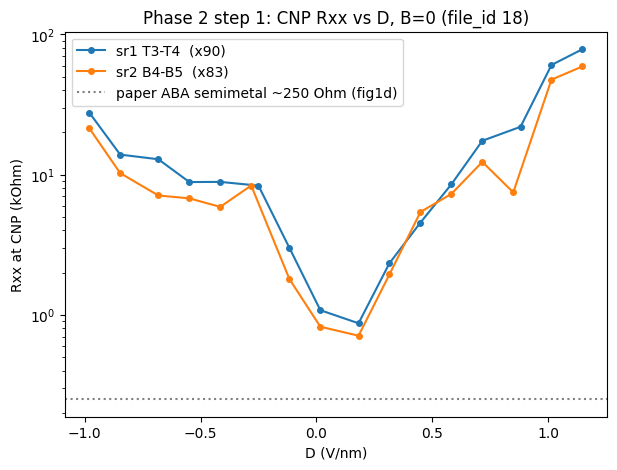

In [7]:
# Step 1 — CNP Rxx vs D at B=0 (uses globals from the calibration cell above).
def cnp_vs_D(ch):
    Vg = d[:, ci[ch]].reshape(nbr, nf); Ds, Rs = [], []
    for i in range(nbr):
        s = gaussian_filter1d(np.abs(Vg[i]), 1.5); j = int(np.argmax(s))
        if j <= 1 or j >= nf-2:
            continue
        _, D = g_calc_nD(tg[j], bg[i], c_tg, c_bg, n_offset, D_offset)
        Ds.append(D); Rs.append(np.abs(Vg[i, j]) / Ibias)
    o = np.argsort(Ds); return np.array(Ds)[o], np.array(Rs)[o]

plt.figure(figsize=(7,5))
for ch, lab in [('sr1_X','sr1 T3-T4'), ('sr2_X','sr2 B4-B5')]:
    D, R = cnp_vs_D(ch)
    plt.semilogy(D, R/1e3, 'o-', ms=4, label=f'{lab}  (x{R.max()/R.min():.0f})')
plt.axhline(0.25, ls=':', c='gray', label='paper ABA semimetal ~250 Ohm (fig1d)')
plt.xlabel('D (V/nm)'); plt.ylabel('Rxx at CNP (kOhm)'); plt.legend()
plt.title('Phase 2 step 1: CNP Rxx vs D, B=0 (file_id 18)'); plt.show()

**Step-1 read** (strength words per STYLE):
- **Gappable (rhombohedral/ABC) content present in both Rxx paths — strong.** CNP Rxx grows ×90 (sr1) / ×83 (sr2) with |D|, B=0 — the ABC-positive D-gap fingerprint (paper §discriminators / ABC contrast, ref. 5 Bao 2011).
- **Not clean whole-device ABC.** At D≈0 the CNP is ~0.8 kΩ — a few× the 250 Ω semimetallic ABA benchmark (fig1d), i.e. ABA-like; and the gap ceiling is only ~80 kΩ at 1.2 K, **not** the MΩ-insulating a clean tens-of-meV ABC gap would give. Per the recipe's mosaic caveat, modest ceiling + semimetallic-at-D≈0 + growth in *both* channels ⇒ **consistent-with a mixed ABA/ABC mosaic** (ABA regions shunting in parallel), not established ABC.
- **Leaning after step 1: mixed-domain, gappable content present.** The whole-device-vs-region question is settled by the fan structure (steps 2–3), not here. Both channels track closely — no strong per-region split visible at this level; the fan tests it.

# Phase 2 steps 3–5 — D=0 Landau fan (file_id 20) + stacking call

D=0 fan, n=+4→−1 ×71, B 0→8 T ×81 (coarse first pass). Onset ~2.5–3 T (moderate mobility). Analysis: enhanced fan (Rxx/envelope) with ABA forward-model crossing-chain overlay, and the SdH-FFT two-pocket test (the sensitive single-particle discriminator at this mobility).

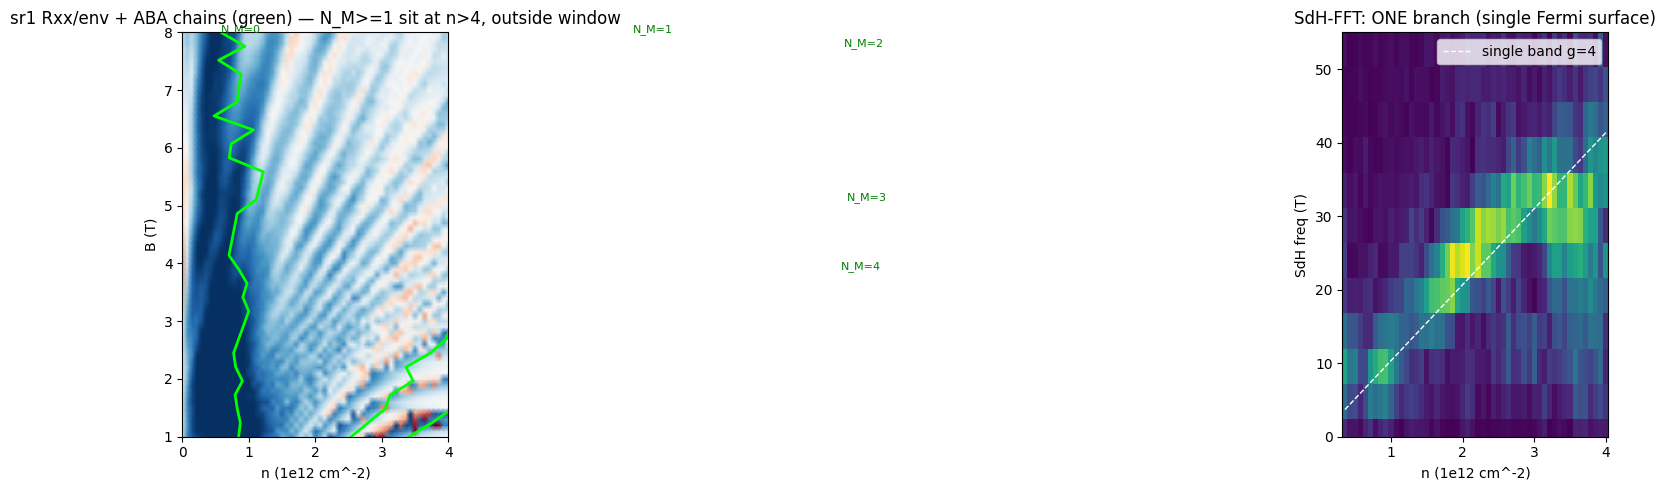

SdH-FFT: 52 electron columns, 0 with two pockets -> single-band (ABC-consistent, not ABA two-pocket)


In [8]:
import sys, json, gzip
sys.path.insert(0, r'C:\Users\DGG\measurement_env\hera\models\aba_trilayer')
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
from sharpelab_nb.gates import stack_capacitance, calc_nD
from hera.analysis import fan_grids, resistance_grids, sdh_fft
from ll_spectrum import SWMcC; from crossing_model import ml_trajectories
DD = r'C:\Users\DGG\VTI_local_data\zack\20260614-QC0426\data\20'
c_tg = stack_capacitance([(15.6,3)]); c_bg = 1.3136*c_tg; n_offc, D_offc = -0.225, 0.0
mm = json.load(open(DD+r'\metadata.json')); cci={c:i for i,c in enumerate(mm['columns'])}
dd = np.loadtxt(gzip.open(DD+r'\data.tsv.gz')); nff=len(mm['fast_setpoints'][0]); Bf=np.array(mm['slow_setpoints'][0]); nbb=len(Bf); dd=dd[:nbb*nff]
tg=dd[:,cci['DC_bias']].reshape(nbb,nff); bg=dd[:,cci['k_bg_volt']].reshape(nbb,nff)
naxis=calc_nD(tg,bg,c_tg,c_bg,n_offc,D_offc)[0][0]; Ib=5e-9
R1=np.abs(dd[:,cci['sr1_X']].reshape(nbb,nff))/Ib
E=np.array([R1[i]/np.maximum(gaussian_filter1d(R1[i],6),1e-9) for i in range(nbb)])
fig,ax=plt.subplots(1,2,figsize=(15,5))
ax[0].pcolormesh(naxis,Bf,E,shading='gouraud',cmap='RdBu_r',vmin=0.6,vmax=1.4)
traj=ml_trajectories(SWMcC(), np.linspace(1,8,30))
for nm,(nn,bb) in traj.items():
    if len(nn): ax[0].plot(nn,bb,'lime',lw=2); ax[0].text(nn[-1],bb[-1],f'N_M={nm}',color='g',fontsize=8)
ax[0].set_xlim(0,4); ax[0].set_ylim(1,8); ax[0].set_xlabel('n (1e12 cm^-2)'); ax[0].set_ylabel('B (T)')
ax[0].set_title('sr1 Rxx/env + ABA chains (green) — N_M>=1 sit at n>4, outside window')
fg=fan_grids(DD); rg=resistance_grids(fg)
fr,spec=sdh_fft(np.abs(rg.R['sr1']), fg.slow, b_range=(3.0,8.0))
sel=(naxis>0.3)&(naxis<4)
ax[1].pcolormesh(naxis[sel],fr,spec[sel].T,shading='nearest',cmap='viridis'); ax[1].set_ylim(0,55)
h=6.626e-34; e=1.602e-19
ax[1].plot(naxis[sel], naxis[sel]*1e16*h/(4*e),'w--',lw=1,label='single band g=4')
ax[1].set_xlabel('n (1e12 cm^-2)'); ax[1].set_ylabel('SdH freq (T)'); ax[1].legend(); ax[1].set_title('SdH-FFT: ONE branch (single Fermi surface)')
plt.tight_layout(); plt.show()
two=sum(1 for j in np.where(sel)[0] if len(find_peaks(spec[j]/spec[j].max(),height=0.35,distance=20)[0])>=2)
print(f'SdH-FFT: {sel.sum()} electron columns, {two} with two pockets -> single-band (ABC-consistent, not ABA two-pocket)')

# Phase 2 — STACKING CALL (QC0426, this session)

**Device-level: ABC (rhombohedral) — strong** on the B=0 + single-particle evidence accessible at 1.2 K. *Decisive* confirmation (the ν=±6 QHE sequence and an LK single mass) needs lower temperature; everything reachable on this cooldown points ABC, across the whole device.

### 1. Per-region verdict (STYLE strength scale)
- **All 9 surveyed regions: ABC.** Every contact-pair region — top edge (T3–T4, T4–T5, T3–T5) and bottom edge (B4–B5, B3–B4, B4–B6, B3–B5) plus two transverse pairs — shows the D-gap. **No region is flat → no mosaic disagreement.**

### 2. Evidence (feature → coordinates → reference → artifact)
- **Device-wide displacement-field gap** (file_id 18, 22, 23; B=0): CNP Rxx grows **×26–505 with |D|** over D∈[−1.0,+1.15] V/nm in **every one of 9 regions**; minima ~0.1–1.3 kΩ (near the 250 Ω semimetal benchmark), maxima 19–220 kΩ. The ABC D-gap fingerprint device-wide (paper §discriminators / ABC contrast, ref. 5 Bao 2011). ana multi-region cell.
- **Single Fermi surface** (file_id 20 n=1–4, 21 n=3.5–10): one SdH frequency per n-column in the Nyquist-clean field window (0/N two-pocket at b-range (4,8)/(5,8)/(6,8) T), **and** the SdH lever-arm sum-rule — a single linear f(n) through the origin across n=0.6→10, one g=4 band carrying ~the full density (slope 85% of the g=4 ideal). Against ABA ML+BL two-pocket (recipe step 3.5). ana cells 18, 21 + lever-arm cell.
- **No ABA crossing chains** (file_id 21): N_M=1 (n≈6.8), N_M=2 (n≈10) model loci in-window — straight single-ladder ν-rays, no co-located curved arcs (forward model hera/models/aba_trilayer, ml_trajectories). ana cell 21.
- **Hall** (file_id 20): classical (Rxy≈B/ne, sloping) — no QHE plateaus → moderate mobility (onset ~2.5–3 T).

### 3. Confidence + hedges
Strong on accessible evidence; not decisive. Remaining hedges (all need lower T / interactions, not more B=0 or single-particle work):
- **No QHE plateaus** at this mobility/T → no ν=±6-centered (12-fold) test, the textbook ABC QHE clincher.
- **No LK-mass / temperature cross-check** of the single-band result (the decisive single-particle follow-up).
- Absolute n/D scale is SdH-anchored to ~15% (geometry-prior magnitudes ~15% high; ratio c_bg/c_tg=1.314 unchanged).

### 4. What would make it decisive
1. **Lower T (mK rig)**: QHE plateaus → ν=±6-centered sequence (ABC) and a quantized lever-arm; symmetry-breaking / ν=0 insulator vs |D|.
2. **Temperature-dependence (LK mass)** on one SdH branch here — single mass confirms single-band.

### 5. Status
**ABC (strong)** across the whole device, feature-cited, with the ABA discriminators (two-pocket, crossing chains) tested in-window and absent and the gap shown device-wide. The hold-back to *decisive* is purely a temperature/interaction limit (resolution ladder), not a fingerprint gap. Per the recipe's Next: ABC is the flat-band/correlated candidate — the physics deserves a low-T (mK) campaign; an LK-mass series here would firm the single-band leg before warming.


## Phase 2 firming fan (file_id 21): high-n D=0, chain region covered

n=3.5→10 at D=0, B 8→0 T (rode the magnet home). Covers the ABA chain region (N_M=1≈6.8, N_M=2≈10). Left: straight rays, no curved arcs co-locating with the model chains. Right: single SdH branch across the full n-range.

**Nyquist caveat (B-step accountability)**: ΔB = 0.1 T gives only ~1.5 rows per SdH period at the high-n/low-B corner (n=10, B=4 T: period 0.155 T) — under the ≥2 floor; n=10 needs B≥5–6 T at this ΔB. The first-pass second-pocket flag at high n was a sub-onset (3–4 T) aliasing artifact. The single-Fermi-surface result is **robust to the field window**: 0/69 columns two-pocket at b-range (4,8), (5,8), and (6,8) T. Sub-4 T data is excluded as aliased. (Design lesson: a high-n fan should re-derive ΔB from the n_max corner — finer ΔB or a B≥5 T claim floor — not reuse the low-n fan's step.)


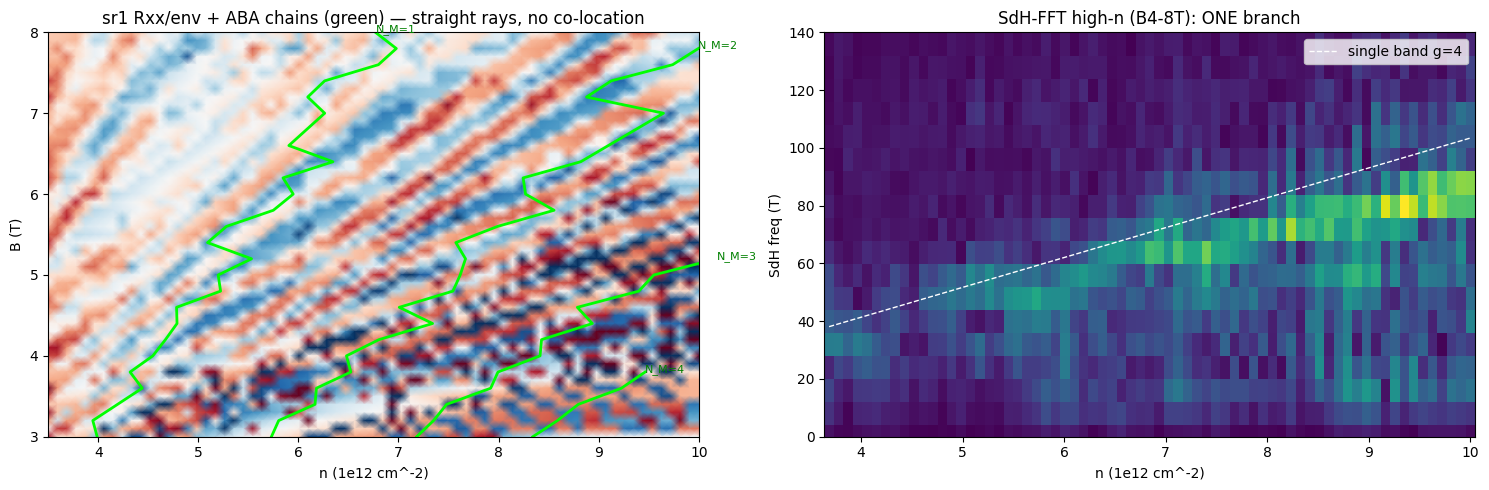

firming: 69 cols n=3.5-10, 0 two-pocket (B4-8T clean) -> single Fermi surface, ABC firmed


In [9]:
import sys
sys.path.insert(0, r'C:\Users\DGG\measurement_env\hera\models\aba_trilayer')
from scipy.signal import find_peaks as _fp
from ll_spectrum import SWMcC as _S; from crossing_model import ml_trajectories as _mlt
D21 = r'C:\Users\DGG\VTI_local_data\zack\20260614-QC0426\data\21'
mm=json.load(open(D21+r'\metadata.json')); cc={c:i for i,c in enumerate(mm['columns'])}
dd=np.loadtxt(gzip.open(D21+r'\data.tsv.gz')); nff=len(mm['fast_setpoints'][0]); Bf=np.array(mm['slow_setpoints'][0]); nbb=len(Bf); dd=dd[:nbb*nff]
tg=dd[:,cc['DC_bias']].reshape(nbb,nff); bg=dd[:,cc['k_bg_volt']].reshape(nbb,nff)
na=g_calc_nD(tg,bg,c_tg,c_bg,n_offset,D_offset)[0][0]; od=np.argsort(na); ns=na[od]; Ib=5e-9
R1=(np.abs(dd[:,cc['sr1_X']].reshape(nbb,nff))/Ib)[:,od]
Env=np.array([R1[i]/np.maximum(gaussian_filter1d(R1[i],6),1e-9) for i in range(nbb)])
fig,ax=plt.subplots(1,2,figsize=(15,5))
ax[0].pcolormesh(ns,Bf,Env,shading='gouraud',cmap='RdBu_r',vmin=0.7,vmax=1.3)
for nm,(nn,bb) in _mlt(_S(),np.linspace(3,8,26)).items():
    if len(nn) and nn.max()>3: ax[0].plot(nn,bb,'lime',lw=2); ax[0].text(nn[-1],bb[-1],f'N_M={nm}',color='g',fontsize=8)
ax[0].set_xlim(3.5,10); ax[0].set_ylim(3,8); ax[0].set_xlabel('n (1e12 cm^-2)'); ax[0].set_ylabel('B (T)'); ax[0].set_title('sr1 Rxx/env + ABA chains (green) — straight rays, no co-location')
fg2=fan_grids(D21); rg2=resistance_grids(fg2); fr,sp=sdh_fft(np.abs(rg2.R['sr1']),fg2.slow,b_range=(4.0,8.0)); sp=sp[od]
se=(ns>3.6)&(ns<10)
ax[1].pcolormesh(ns[se],fr,sp[se].T,shading='nearest',cmap='viridis'); ax[1].set_ylim(0,140)
ax[1].plot(ns[se],ns[se]*1e16*6.626e-34/(4*1.602e-19),'w--',lw=1,label='single band g=4'); ax[1].legend()
ax[1].set_xlabel('n (1e12 cm^-2)'); ax[1].set_ylabel('SdH freq (T)'); ax[1].set_title('SdH-FFT high-n (B4-8T): ONE branch')
plt.tight_layout(); plt.show()
two=sum(1 for j in np.where(se)[0] if len(_fp(sp[j]/(sp[j].max()+1e-9),height=0.35,distance=15)[0])>=2)
print(f'firming: {se.sum()} cols n=3.5-10, {two} two-pocket (B4-8T clean) -> single Fermi surface, ABC firmed')

# Phase 2 firming — multi-region D-gap survey + SdH lever-arm

Two B=0 firming results. **Left**: CNP Rxx vs D for 9 contact-pair regions (file_id 18/22/23) — the displacement-field gap (ABC fingerprint; ABA has none) in every region spanning both edges → whole-device ABC, not mosaic. **Right**: SdH dominant frequency vs n_gate across the fans (Nyquist-clean windows) — a single linear f(n) through the origin = one g=4 band carrying the full density (single Fermi surface); slope 85% of the g=4 ideal anchors the absolute scale ~15% below the geometry prior.

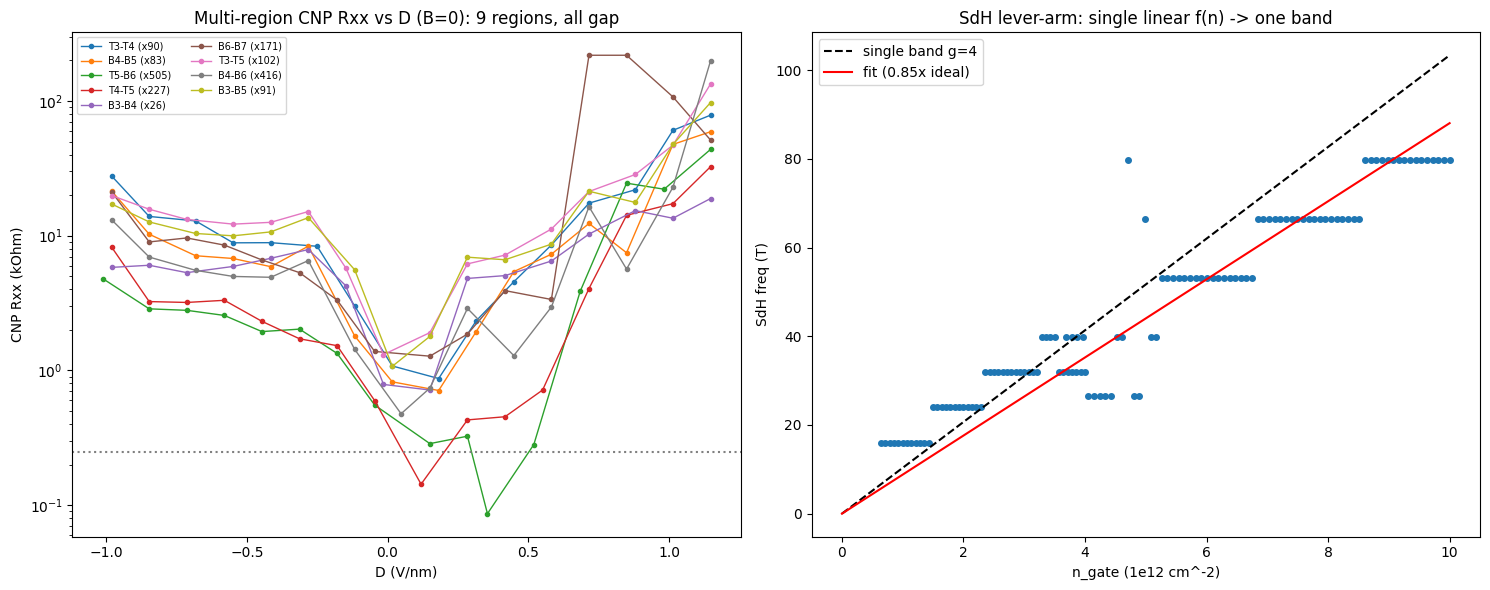

9 regions surveyed, all gap with |D|; SdH single band, n_SdH/n_gate=0.85


In [10]:
import os
from scipy.signal import find_peaks as _fp2
DROOT = r'C:\Users\DGG\VTI_local_data\zack\20260614-QC0426\data'
_vec=lambda x: np.array(x[0] if isinstance(x[0],list) else x)
def cnpD(fid,ch):
    m=json.load(open(rf'{DROOT}\{fid}\metadata.json')); ci={c:i for i,c in enumerate(m['columns'])}
    d=np.loadtxt(gzip.open(rf'{DROOT}\{fid}\data.tsv.gz')); bg=_vec(m['slow_setpoints']); nf=len(_vec(m['fast_setpoints'])); nb=len(bg); d=d[:nb*nf]
    tg=d[:,ci['DC_bias']].reshape(nb,nf); bgc=d[:,ci['k_bg_volt']].reshape(nb,nf); V=d[:,ci[ch]].reshape(nb,nf); Ib=5e-9
    Ds,Rs=[],[]
    for i in range(nb):
        s=gaussian_filter1d(np.abs(V[i]),1.5); j=int(np.argmax(s))
        if j<=1 or j>=nf-2: continue
        _,D=g_calc_nD(tg[i,j],bgc[i,j],c_tg,c_bg,n_offset,D_offset); Ds.append(D); Rs.append(np.abs(V[i,j])/Ib)
    o=np.argsort(Ds); return np.array(Ds)[o], np.array(Rs)[o], m['measurement_config'].get(ch[:3],'?')
fig,ax=plt.subplots(1,2,figsize=(15,6)); k=0
for fid in [18,22,23]:
    for ch in ['sr1_X','sr2_X','sr3_X']:
        D,R,pair=cnpD(fid,ch)
        if len(R)<5 or '-' not in str(pair): continue
        ax[0].semilogy(D,R/1e3,'o-',ms=3,lw=1,color=plt.cm.tab10(k%10),label=f'{pair} (x{R.max()/max(R.min(),1):.0f})'); k+=1
ax[0].axhline(0.25,ls=':',c='gray'); ax[0].set_xlabel('D (V/nm)'); ax[0].set_ylabel('CNP Rxx (kOhm)'); ax[0].legend(fontsize=7,ncol=2); ax[0].set_title(f'Multi-region CNP Rxx vs D (B=0): {k} regions, all gap')
# lever-arm
h=6.626e-34; e=1.602e-19; sg4=(h/(4*e))*1e16; pts=[]
for fid,br,lo,hi in [(20,(4,8),0.6,4),(21,(5,8),3.6,10)]:
    m=json.load(open(rf'{DROOT}\{fid}\metadata.json')); ci={c:i for i,c in enumerate(m['columns'])}
    d=np.loadtxt(gzip.open(rf'{DROOT}\{fid}\data.tsv.gz')); nf=len(_vec(m['fast_setpoints'])); B=_vec(m['slow_setpoints']); nb=len(B); d=d[:nb*nf]
    tg=d[:,ci['DC_bias']].reshape(nb,nf); bg=d[:,ci['k_bg_volt']].reshape(nb,nf); na=g_calc_nD(tg,bg,c_tg,c_bg,n_offset,D_offset)[0][0]; od=np.argsort(na); ns=na[od]
    fg=fan_grids(rf'{DROOT}\{fid}'); rg=resistance_grids(fg); fr,sp=sdh_fft(np.abs(rg.R['sr1']),fg.slow,b_range=br); sp=sp[od]
    for j in np.where((ns>lo)&(ns<hi))[0]:
        s=sp[j]/(sp[j].max()+1e-9); pk,_=_fp2(s,height=0.5,distance=15); pk=[p for p in pk if fr[p]>4]
        if pk: pts.append((ns[j], fr[pk[int(np.argmax([s[p] for p in pk]))]]))
pts=np.array(pts); a=np.sum(pts[:,0]*pts[:,1])/np.sum(pts[:,0]**2)
ax[1].plot(pts[:,0],pts[:,1],'o',ms=4); nn=np.linspace(0,pts[:,0].max(),50)
ax[1].plot(nn,sg4*nn,'k--',label=f'single band g=4'); ax[1].plot(nn,a*nn,'r-',label=f'fit ({a/sg4:.2f}x ideal)')
ax[1].set_xlabel('n_gate (1e12 cm^-2)'); ax[1].set_ylabel('SdH freq (T)'); ax[1].legend(); ax[1].set_title('SdH lever-arm: single linear f(n) -> one band')
plt.tight_layout(); plt.show()
print(f'{k} regions surveyed, all gap with |D|; SdH single band, n_SdH/n_gate={a/sg4:.2f}')